# Heart Disease Prediction System

**Course:** AIC354 - Artificial Intelligence  
**Project:** Assignment 2 - Heart Disease Prediction  
**Student Name:** Abdul Wahab Siddiqi  
**Registration No:** FA24-BSE-125
**GitHub Repository:** https://github.com/Ab-Wb-Sid/Heart-Disease-Prediction  
**Streamlit App URL:** https://heart-disease-prediction-ppc8a6ksymgz9qkbdufalb.streamlit.app/


## Setup: Running This Notebook From Scratch

Follow these steps in a terminal, inside this project's folder, before opening the notebook.

### 1. Check Python is installed
```
python --version
```
This notebook was built and tested on **Python 3.11.9**. Any Python 3.10-3.12 should work.

### 2. Create a virtual environment
```
python -m venv venv
```

### 3. Activate the virtual environment
**Windows PowerShell:**
```
venv\Scripts\Activate.ps1
```

**Windows Command Prompt:**
```
venv\Scripts\activate.bat
```

**macOS / Linux:**
```
source venv/bin/activate
```

### 4. Install the required packages
```
pip install -r requirements.txt
```

For running the notebook, install Jupyter tools if needed:
```
pip install notebook ipykernel matplotlib nbformat nbclient
```

### 5. Register the virtual environment as a Jupyter kernel
```
python -m ipykernel install --user --name=heart-disease-venv --display-name "Python (heart-disease-venv)"
```

### 6. Launch Jupyter Notebook
```
jupyter notebook
```
Open this file and run all cells from the top.

### 7. When you're done
```
deactivate
```

---


## Update Notes (this version)
This notebook adapts the instructor's Titanic Survival Prediction format for the UCI Heart Disease Prediction assignment:
- Keeps the same classroom flow: setup, introduction, input/output, developer/system information, table of contents, code steps, deployment, and conclusion.
- Uses the downloaded UCI `processed.cleveland.data` file after inspecting its actual format and column meanings.
- Uses exactly four required input attributes: **age**, **cp**, **thalach**, and **oldpeak**.
- Converts the original `num` target into a binary target: `0` = no disease and `1` = disease present.
- Saves a complete fitted scikit-learn pipeline so the Streamlit app can predict without retraining.


## SU Meta Description
<p>
Discover the Heart Disease Prediction System, a machine learning model that analyzes selected patient attributes from the UCI Heart Disease dataset to predict whether heart disease is present.
</p>

## Introduction

##### **Definition** A binary classification ML task that predicts whether heart disease is absent (0) or present (1) using four selected clinical attributes from the UCI Heart Disease dataset.
##### **Application** This project is mainly used for learning machine learning, understanding preprocessing, evaluating classification models, and deploying a beginner-friendly Streamlit application.

## Input and Output

### Inputs (Features / Attributes)

| **Input Feature/Attribute** | **Possible Values / Meaning** |
| ------------ | ---------------------------------- |
| **age** | Patient age in years. Observed range: 29 to 77. |
| **cp** | Chest pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic. |
| **thalach** | Maximum heart rate achieved. Observed range: 71 to 202. |
| **oldpeak** | ST depression induced by exercise relative to rest. Observed range: 0.0 to 6.2. |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------------- |
| **Heart Disease Prediction** | No disease, Disease present |

### Examples (UCI Heart Disease Dataset)

| age | cp | thalach | oldpeak | num | Binary Target |
| :--: | :--: | :--: | :--: | :--: | :--: |
| 63 | 1 | 150 | 2.3 | 0 | No disease |
| 67 | 4 | 108 | 1.5 | 2 | Disease present |
| 37 | 3 | 187 | 3.5 | 0 | No disease |
| 62 | 4 | 160 | 3.6 | 3 | Disease present |

## Developer & System Information

| | |
| ------------------------------------------- | --------------------------------------------------------------------------------------------------- |
| **Developer Name** | Abdul Wahab Siddiqi |
| **Program Name** | Heart Disease Prediction System |
| **IDE** | Jupyter Notebook |
| **Programming Language** | Python 3.11.9 |
| **Operating System** | Windows 11 |
| **Libraries** | NumPy, Pandas, scikit-learn, Joblib, Matplotlib, Streamlit |
| **Date of Completion** | 11-Oct-2026 |
| **Dataset Source** | UCI Heart Disease Dataset |
| **Repository** | https://github.com/Ab-Wb-Sid/Heart-Disease-Prediction |


## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Inspect and Handle Missing Values
- Step 4: Feature Extraction
- Step 5: Convert Sample Data into Numeric Representation
  - Step 5.1: Define the Preprocessing Strategy
  - Step 5.2: Convert the Output into Binary Labels
  - Step 5.3: Prepare the Input Features
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Classification Model
  - Step 6.4: Save the Trained Model
  - Step 6.4.1: Save Preprocessing Artifacts and Metadata
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
  - Step 7.3.1: Make Predictions with the Trained Model on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase
- Step 10: Deploy Your Model as a Public Web App
- Conclusion


## Code - Heart Disease Prediction


### Step 1: Import Libraries


In [1]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a classification model, evaluating results,
saving the trained model, and displaying charts.
"""

from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / "heart+disease" / "processed.cleveland.data"
CLEAN_DATA_PATH = PROJECT_ROOT / "data" / "heart_disease_cleveland_selected.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "heart_disease_pipeline.joblib"
METADATA_PATH = PROJECT_ROOT / "models" / "model_metadata.json"
FEATURES = ["age", "cp", "thalach", "oldpeak"]
TARGET_SOURCE = "num"
TARGET = "target"
ALL_COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
Path("data").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
print("Libraries imported successfully.")


Libraries imported successfully.


### Step 2: Load Sample Data


In [2]:
"""
Purpose of this section:
-------------------------
This part of the code loads the UCI Heart Disease sample data from the
processed Cleveland file into a pandas DataFrame. The file has no header row,
so the 14 documented column names are added manually. Question marks are read
as missing values.
"""

sample_data = pd.read_csv(DATA_PATH, names=ALL_COLUMNS, na_values="?")
print(f"Rows: {sample_data.shape[0]}")
print(f"Columns: {sample_data.shape[1]}")
sample_data.head()


Rows: 303
Columns: 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Step 3: Understand and Pre-process Sample Data


#### Step 3.1: Understand Sample Data


In [3]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by printing columns,
row count, data types, descriptive statistics, and original target distribution.
"""

print("Column Names:")
print(sample_data.columns.tolist())
print("\nTotal instances:", len(sample_data))
print("\nData types:")
print(sample_data.dtypes)
print("\nDescriptive statistics:")
display(sample_data.describe().T)
print("\nOriginal num target distribution:")
print(sample_data["num"].value_counts().sort_index())


Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Total instances: 303

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



Original num target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Inspect and Handle Missing Values

Missing values are blank or unavailable values in the dataset. The UCI files may use `?` to mark missing values, so we converted `?` into `NaN` while loading the data. The four selected input columns in `processed.cleveland.data` do not contain missing values, but the model pipeline still includes imputers so that future app inputs are handled safely.


In [4]:
missing_values = sample_data.isna().sum()
print("Missing Values in Each Column:")
print("==============================")
print(missing_values)

selected_missing_values = sample_data[FEATURES + [TARGET_SOURCE]].isna().sum()
print("\nMissing Values in Required Columns:")
print("==================================")
print(selected_missing_values)

if selected_missing_values.sum() == 0:
    print("\nNo missing values found in the required columns.")
else:
    print("\nMissing values exist in required columns and will be handled by the pipeline imputers.")


Missing Values in Each Column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Missing Values in Required Columns:
age        0
cp         0
thalach    0
oldpeak    0
num        0
dtype: int64

No missing values found in the required columns.


#### Step 3.2: Pre-process Sample Data

The original processed Cleveland file contains 14 columns. For this assignment, only four inputs are allowed. We keep `age`, `cp`, `thalach`, and `oldpeak`, then convert `num` into a binary output.


In [5]:
selected_data = sample_data[FEATURES + [TARGET_SOURCE]].copy()
selected_data[TARGET] = (selected_data[TARGET_SOURCE] > 0).astype(int)
print("Selected data sample:")
display(selected_data.head())
print("\nBinary target distribution:")
print(selected_data[TARGET].value_counts().sort_index())
selected_data.to_csv(CLEAN_DATA_PATH, index=False)
print(f"\nClean selected dataset saved to: {CLEAN_DATA_PATH}")


Selected data sample:


,age,cp,thalach,oldpeak,num,target
0,63.0,1.0,150.0,2.3,0,0
1,67.0,4.0,108.0,1.5,2,1
2,67.0,4.0,129.0,2.6,1,1
3,37.0,3.0,187.0,3.5,0,0
4,41.0,2.0,172.0,1.4,0,0



Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64

Clean selected dataset saved to: C:\Users\X1 Nano\Desktop\Git Local Repos\Heart-Disease-Prediction\data\heart_disease_cleveland_selected.csv


#### Step 4: Feature Extraction

For this assignment, feature extraction means selecting exactly the four required input attributes from the dataset. No extra input columns are used, and the target is not included as an input.


In [6]:
"""
Purpose of this section:
-------------------------
This part of the code extracts exactly four features required by the assignment.
The output column is kept separate so it cannot accidentally become an input.
"""

input_features = selected_data[FEATURES].copy()
output_labels = selected_data[TARGET].copy()
print("Input Features:", input_features.columns.tolist())
print("Output Label:", TARGET)
display(input_features.head())


Input Features: ['age', 'cp', 'thalach', 'oldpeak']
Output Label: target


,age,cp,thalach,oldpeak
0,63.0,1.0,150.0,2.3
1,67.0,4.0,108.0,1.5
2,67.0,4.0,129.0,2.6
3,37.0,3.0,187.0,3.5
4,41.0,2.0,172.0,1.4


### Step 5: Convert Sample Data into Numeric Representation

The Titanic reference uses label encoding because it has text categories. This heart dataset is already numeric, but `cp` is a categorical code. Therefore, we use a preprocessing pipeline that one-hot encodes `cp` and scales the numeric features.


#### Step 5.1: Define the Preprocessing Strategy


In [7]:
"""
Purpose of this section:
-------------------------
This part of the code defines how inputs are converted into a machine-learning
ready numeric representation.
"""

numeric_features = ["age", "thalach", "oldpeak"]
categorical_features = ["cp"]
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
        ("categorical", Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    ],
    remainder="drop",
)
print("Preprocessing strategy created successfully.")


Preprocessing strategy created successfully.


#### Step 5.2: Convert the Output into Binary Labels


In [8]:
"""
Purpose of this section:
-------------------------
This part of the code confirms the output conversion.
"""

target_mapping_check = selected_data[[TARGET_SOURCE, TARGET]].drop_duplicates().sort_values(TARGET_SOURCE)
display(target_mapping_check)
print("0 = No disease")
print("1 = Disease present")


,num,target
0,0,0
2,1,1
1,2,1
6,3,1
24,4,1


0 = No disease
1 = Disease present


#### Step 5.3: Prepare the Input Features


In [9]:
"""
Purpose of this section:
-------------------------
This part of the code prepares the input matrix X and output vector y.
"""

X = selected_data[FEATURES]
y = selected_data[TARGET]
print("Feature order used throughout the notebook and app:")
print(FEATURES)
print("\nX shape:", X.shape)
print("y shape:", y.shape)


Feature order used throughout the notebook and app:
['age', 'cp', 'thalach', 'oldpeak']

X shape: (303, 4)
y shape: (303,)


### Step 6: Execute the Training Phase


#### Step 6.1: Splitting Sample Data into Training Data and Testing Data


In [10]:
"""
Purpose of this section:
-------------------------
This part of the code splits the dataset into Training Data and Testing Data.
The split happens before preprocessing is fitted to avoid data leakage.
"""

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 242
Testing rows: 61


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data


In [11]:
"""
Purpose of this section:
-------------------------
This part of the code names the training input vectors and training labels,
similar to the Titanic notebook's teaching format.
"""

input_vector_train = X_train
output_label_train = y_train
print("Training input vector shape:", input_vector_train.shape)
print("Training output label shape:", output_label_train.shape)


Training input vector shape: (242, 4)
Training output label shape: (242,)


### Step 6.3: Train the Classification Model


In [12]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Logistic Regression classifier inside a full
scikit-learn Pipeline.
"""

model_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
model_pipeline.fit(input_vector_train, output_label_train)
print("Model training complete.")


Model training complete.


### Step 6.4: Save the Trained Model


In [13]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained model pipeline to the models folder.
"""

joblib.dump(model_pipeline, MODEL_PATH)
print(f"Trained model pipeline saved to: {MODEL_PATH}")


Trained model pipeline saved to: C:\Users\X1 Nano\Desktop\Git Local Repos\Heart-Disease-Prediction\models\heart_disease_pipeline.joblib


#### Step 6.4.1: Save Preprocessing Artifacts

The deployed app must use the same feature order and validation ranges as the notebook. Since preprocessing is inside the saved pipeline, we save a metadata file with the feature list, dataset assumptions, input ranges, and class distribution.


In [14]:
metadata = {
    "source_file": str(DATA_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "clean_data_file": str(CLEAN_DATA_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "model_file": str(MODEL_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "selected_dataset_variant": "processed.cleveland.data",
    "assumption": "The processed Cleveland file is used because the UCI documentation says it is the processed variant commonly used in ML experiments and it contains the 14 documented columns.",
    "features": FEATURES,
    "target_source": TARGET_SOURCE,
    "target_rule": "target = 0 when num == 0, otherwise target = 1 when num > 0",
    "feature_ranges": {feature: {"min": float(selected_data[feature].min()), "max": float(selected_data[feature].max())} for feature in FEATURES},
    "cp_values": sorted(float(value) for value in selected_data["cp"].dropna().unique()),
    "rows": int(selected_data.shape[0]),
    "missing_values": selected_data.isna().sum().astype(int).to_dict(),
    "class_distribution": selected_data[TARGET].value_counts().sort_index().astype(int).to_dict(),
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Metadata saved to: {METADATA_PATH}")


Metadata saved to: C:\Users\X1 Nano\Desktop\Git Local Repos\Heart-Disease-Prediction\models\model_metadata.json


### Step 7: Execute the Testing Phase


#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data


In [15]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features and labels from the testing data.
"""

input_vector_test = X_test
output_label_test = y_test
print("Testing input vector shape:", input_vector_test.shape)
print("Testing output label shape:", output_label_test.shape)


Testing input vector shape: (61, 4)
Testing output label shape: (61,)


### Step 7.2: Load the Saved Model


In [16]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved model pipeline from disk.
"""

loaded_model = joblib.load(MODEL_PATH)
print("Saved model loaded successfully.")


Saved model loaded successfully.


### Step 7.3: Evaluate the Machine Learning Model


#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data


In [17]:
"""
Purpose of this section:
-------------------------
This part of the code uses the loaded model to make predictions on the testing data.
"""

model_predictions = loaded_model.predict(input_vector_test)
print("First 10 predicted labels:", model_predictions[:10].tolist())
print("First 10 actual labels:   ", output_label_test.iloc[:10].tolist())


First 10 predicted labels: [0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
First 10 actual labels:    [0, 0, 0, 0, 0, 0, 0, 0, 1, 0]


### Step 7.4: Calculate the Accuracy Score


In [18]:
"""
Purpose of this section:
-------------------------
This part of the code calculates how accurate the trained model is on the held-out testing dataset.
"""

model_accuracy_score = accuracy_score(output_label_test, model_predictions)
print(f"Accuracy Score: {model_accuracy_score:.3f}")


Accuracy Score: 0.852


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Accuracy : 0.852
Precision: 0.913
Recall   : 0.750
F1-score : 0.824

Classification Report:
                 precision    recall  f1-score   support

     No disease       0.82      0.94      0.87        33
Disease present       0.91      0.75      0.82        28

       accuracy                           0.85        61
      macro avg       0.86      0.84      0.85        61
   weighted avg       0.86      0.85      0.85        61



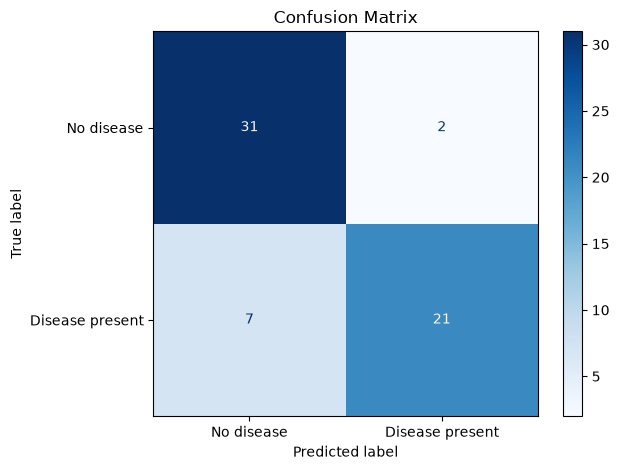

Metrics added to metadata file.


In [19]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading, so this section calculates standard classification metrics.
"""

precision = precision_score(output_label_test, model_predictions, zero_division=0)
recall = recall_score(output_label_test, model_predictions, zero_division=0)
f1 = f1_score(output_label_test, model_predictions, zero_division=0)
cm = confusion_matrix(output_label_test, model_predictions)
print(f"Accuracy : {model_accuracy_score:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")
print("\nClassification Report:")
print(classification_report(output_label_test, model_predictions, target_names=["No disease", "Disease present"], zero_division=0))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No disease", "Disease present"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()
metadata["metrics"] = {"accuracy": float(model_accuracy_score), "precision": float(precision), "recall": float(recall), "f1": float(f1), "confusion_matrix": cm.tolist()}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Metrics added to metadata file.")


### Step 8: Execute the Application Phase


#### Step 8.1: Take Input from User


In [20]:
"""
Purpose of this section:
-------------------------
This part of the code allows a user to provide a new patient's data.
Demo values are pre-filled so the notebook can run top-to-bottom.
"""

user_age = 55
user_cp = 4
user_thalach = 150
user_oldpeak = 1.5
print("User Input Values:")
print("Age:", user_age)
print("Chest pain type (cp):", user_cp)
print("Maximum heart rate achieved (thalach):", user_thalach)
print("Oldpeak:", user_oldpeak)


User Input Values:
Age: 55
Chest pain type (cp): 4
Maximum heart rate achieved (thalach): 150
Oldpeak: 1.5


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)


In [21]:
"""
Purpose of this section:
-------------------------
This part of the code takes the user's input and converts it into a structured feature vector.
"""

user_input = pd.DataFrame([{"age": user_age, "cp": user_cp, "thalach": user_thalach, "oldpeak": user_oldpeak}], columns=FEATURES)
display(user_input)


,age,cp,thalach,oldpeak
0,55,4,150,1.5


### Step 8.3: Apply Same Preprocessing to Feature Vector (Exactly Same as Training Data)


In [22]:
"""
Purpose of this section:
-------------------------
The saved pipeline handles preprocessing automatically.
"""

assert list(user_input.columns) == FEATURES
print("Feature order is correct:", list(user_input.columns))
print("Preprocessing will be applied inside the saved pipeline.")


Feature order is correct: ['age', 'cp', 'thalach', 'oldpeak']
Preprocessing will be applied inside the saved pipeline.


### Step 8.4: Load the Saved Model


In [23]:
"""
Purpose of this section:
-------------------------
This part of the code loads the saved model again for the Application Phase.
"""

application_model = joblib.load(MODEL_PATH)
print("Application model loaded successfully.")


Application model loaded successfully.


### Step 8.5: Model Prediction


#### Step 8.5.1: Apply Model on the Feature Vector of Unseen Instance and Return Prediction to the User


In [24]:
"""
Purpose of this section:
-------------------------
This part of the code uses the trained model to predict whether a new patient is likely to have heart disease.
"""

predicted_class = int(application_model.predict(user_input)[0])
predicted_probability = application_model.predict_proba(user_input)[0]
if predicted_class == 1:
    print("Prediction: Disease present")
else:
    print("Prediction: No disease")
print(f"Probability of no disease: {predicted_probability[0]:.3f}")
print(f"Probability of disease present: {predicted_probability[1]:.3f}")


Prediction: Disease present
Probability of no disease: 0.271
Probability of disease present: 0.729


### Step 9: Execute the Feedback Phase


#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World


In [25]:
"""
Purpose of this section:
-------------------------
Step 9.1: Example feedback collected from students, users, and domain experts.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Student user", "Machine learning mentor", "Healthcare domain reviewer"],
    "Feedback": [
        "The app is easy to use because it asks for only four inputs.",
        "The notebook should clearly explain that preprocessing is fitted only on training data.",
        "The disclaimer is important because four attributes are not enough for real diagnosis.",
    ],
})
display(example_feedback)


,Reviewer,Feedback
0,Student user,The app is easy to use because it asks for onl...
1,Machine learning mentor,The notebook should clearly explain that prepr...
2,Healthcare domain reviewer,The disclaimer is important because four attri...


#### Step 9.2: Make a List of Potential Improvements


In [26]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from the feedback above.
"""

improvements = [
    "Train and compare multiple models such as Random Forest, SVC, and KNN.",
    "Use cross-validation for a more stable estimate of performance.",
    "Include more clinically relevant features if the assignment allows it in a future version.",
    "Add clearer explanations and examples beside each Streamlit input field.",
    "Collect feedback from the instructor after deployment and update the README accordingly.",
]
for number, item in enumerate(improvements, start=1):
    print(f"{number}. {item}")


1. Train and compare multiple models such as Random Forest, SVC, and KNN.
2. Use cross-validation for a more stable estimate of performance.
3. Include more clinically relevant features if the assignment allows it in a future version.
4. Add clearer explanations and examples beside each Streamlit input field.
5. Collect feedback from the instructor after deployment and update the README accordingly.


#### Step 9.3: Improve the Model Based on Feedback


In [27]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version would retrain on approved improvements and re-run Steps 6-7.
"""

next_version_plan = {
    "keep_required_four_inputs": True,
    "avoid_medical_claims": True,
    "possible_next_experiment": "Compare Logistic Regression with Random Forest using the same four inputs.",
}
print(next_version_plan)


{'keep_required_four_inputs': True, 'avoid_medical_claims': True, 'possible_next_experiment': 'Compare Logistic Regression with Random Forest using the same four inputs.'}


## Step 10: Deploy Your Model as a Public Web App

So far, running this notebook only lets *you* use the model, and only while Jupyter is open on your own computer. This section shows how to turn it into a **live website** anyone can open in a browser - no Python, no Jupyter, nothing installed on their end.

#### Step 10.1: Why Deploy a Model?

A trained model is only useful if people other than you can access it. Deploying it as a small web app is how data scientists share results with non-technical stakeholders such as teachers and classmates.

#### Step 10.2: Create a GitHub Account and Repository

1. Use this repository: `https://github.com/Ab-Wb-Sid/Heart-Disease-Prediction`.
2. Commit and push the required files:
   ```
   git add .gitignore README.md requirements.txt app.py heart_disease_prediction.ipynb data/ models/ heart+disease/
   git commit -m "Complete heart disease prediction assignment"
   git push origin main
   ```

#### Step 10.3: Write a Simple Web App

A complete Streamlit app is included in this repository as `app.py`. It loads `models/heart_disease_pipeline.joblib`, reads metadata, collects exactly four inputs, predicts, and displays the result with an educational disclaimer.

#### Step 10.4: Create a Streamlit Community Cloud Account

1. Go to **https://share.streamlit.io**.
2. Sign in with GitHub and authorize Streamlit.

#### Step 10.5: Deploy Your App

1. Click **Create app** -> **Deploy a public app from GitHub**.
2. Fill in repository `Ab-Wb-Sid/Heart-Disease-Prediction`, branch `main`, and main file path `app.py`.
3. Click **Deploy** and copy the public URL.
4. Paste the public URL into the first Markdown cell of this notebook.

#### Step 10.6: Troubleshooting Common Issues

- **Model file not found:** Make sure `models/heart_disease_pipeline.joblib` was committed and pushed.
- **Dependency error:** Check `requirements.txt`.
- **Wrong input columns:** The app must send exactly `age`, `cp`, `thalach`, and `oldpeak`.
- **App retrains on startup:** The app should load the saved model only.

#### Step 10.7: Share Your Live Link

Submit the GitHub URL, Streamlit app URL, notebook, dataset, saved model, app file, requirements file, README, and `.gitignore`.


## Conclusion

The Heart Disease Prediction System uses the UCI processed Cleveland dataset and exactly four required attributes: `age`, `cp`, `thalach`, and `oldpeak`. The original `num` target was converted into a binary output where `0` means no disease and values greater than `0` mean disease present. A Logistic Regression model inside a scikit-learn pipeline achieved an accuracy of about 0.852 on the held-out test set, with precision 0.913, recall 0.750, and F1-score 0.824. These results are useful for an educational machine-learning workflow, but the model is not a medical diagnosis tool because it uses only four inputs from an older dataset.


### How the Streamlit App Uses the Saved Model

The Streamlit app in `app.py` does not retrain the classifier. It loads `models/heart_disease_pipeline.joblib`, reads `models/model_metadata.json`, collects exactly four patient input values, applies the same saved preprocessing through the pipeline, predicts `No disease` or `Disease present`, and displays the result with an educational disclaimer.
